# DSA8021 Machine Learning Coursework 2026


Assessment will be based on conceptual equivalencies and academic judgement. The study regulations are found here -> https://www.qub.ac.uk/directorates/media/Media,837249,smxx.pdf


# Part 1: Theory of Neural Networks (total of 25 marks)

## Neural Network Basics (5 Marks)

Consider the network architecture shown below, along with weights(note that weights $w_{5}$ and $w_{6}$ are biases). This network is used for a classification problem, and all of the activation functions are sigmoids:
$$ f(m) = \frac{1}{1 + e^{-m}} $$

![NN architecture](Coursework_Network.png "Neural Network")

When the input $x_{1} = 1$, $x_{2} = 1$ is given to the network, the target output is $z = 1$.

- A) Calculate the output of the network for the given input.
- B) With justification, choose an error function for the network and evaluate this error function given the target value and the output you have calculated.
- C) To improve the error, should weight $w_{7}$ be increased or decreased? Note that you do not need to perform an explicit calculation.
- D) Describe two changes you could make to the network architecture that you would expect to improve its performance. Which of these would you expect to lead to the most improvement?


## Deep Learning (20 Marks, 10 per question)
Choose **two** of the following questions to answer. In each case, your answer should be **no more than 250 words**, and should include a figure:
- A) Explain what is meant by _overfitting_ in the context of training neural networks, and describe two methods for avoiding overfitting.
- B) Describe a method by which invariances in the training data can be taken into account when training a regression problem? How does your answer differ for a classification problem?
- C) Explain the function of _convolutional layers_ and _pooling layers_ in a convolutional neural network.
- D) Draw a schematic figure of a generative adversarial network (GAN): why are two networks needed in a GAN, and why do they compete with each other?

# Part 2: Practical Scenario (75 Marks)
## Build an image classifier

In this scenario you have started work for a company that wants you to develop a machine learning tool for determining how many dots are on the visible surface of a dice. Your work will be assessed by two people with different motivations:
-  The client, who is mainly interested in the  accuracy of your model at classiying the dice images
-  Your supervisor who mainly cares about what methods you use and why.
  
Therefore, although final performance of the model is important, it is also necessary to explain your approach and justify your choices.

The problem can be broken down into the following tasks:
- A) Data exploration and pre-processing
- B) Model building
- C) Training and validation
- D) Evaluation of the performance on test data

All of your answers should be written in this notebook, which should be able to run without error.

Use "markdown" cells to include explanations of your work. 

This notebook, along with your saved model should be uploaded to canvas as your submission.

## Data loading
Below, the dataset is loaded as a pandas dataframe. It is up to you to decide how to manipulate this data and how to use it to solve the problem. The 'label' column contains labels for each image. The 'pixel_1', 'pixel_2', etc columns contain the pixel values for the images of the dice. These were originally taken from a 28 x 28 size monochrome image.

In [1]:
import numpy as np
import pandas as pd

# the following code loads the training and validation data
data_df = pd.read_csv('data.csv')
data_df

,label,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,...,pixel_774,pixel_775,pixel_776,pixel_777,pixel_778,pixel_779,pixel_780,pixel_781,pixel_782,pixel_783
0,5,110,107,103,100,97,94,90,87,84,...,29,26,22,19,16,13,9,6,3,0
1,5,10,10,10,9,9,8,8,8,7,...,111,100,86,81,78,77,76,75,75,75
2,1,0,0,1,1,2,3,3,4,5,...,61,62,63,63,64,65,65,66,67,67
3,1,10,11,12,13,14,15,15,16,17,...,17,16,17,18,19,20,21,22,23,23
4,6,29,28,27,25,24,23,22,21,20,...,19,18,17,16,15,14,12,11,10,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
379,4,0,0,0,1,1,2,2,2,3,...,53,53,54,54,55,55,55,56,56,57
380,3,15,15,14,14,13,12,12,11,11,...,56,55,55,54,54,53,52,52,51,51
381,3,20,19,18,18,17,16,15,15,14,...,40,40,39,38,37,36,36,35,34,33
382,2,40,41,42,42,43,44,45,45,46,...,13,13,14,15,16,16,17,18,19,19


# Task A: Data exploration, model selection and data pre-processing
In this part you should:
- a) Describe the shape of the dataset
- b) Examine the image data and describe qualitatively
- c) Determine indexes for the classification task
- d) Describe how you are going to proceed, what type of model you are going to use and why
- e) Perform any splitting and pre-processing on the data that you need for your approach


## a) Dataset Shape

The dataset contains images of dice represented by flattend pixel vectors.

- Each row corresponds to a single image,
- The label column represents the number of visible dots on the dice (1-6),
- The remaining columns (`pixel_0` - `pixel_783`) represent greyscale pixel intensities.

Since there are 784 pixel values the original images must be 28x28.

Dataset shape: (384, 785)
Number of images: 384
Pixels per image: 784
Image size: 28 x 28
Pixel value range: 0 - 255

Class distribution:


,label,count
0,1,63
1,2,65
2,3,58
3,4,66
4,5,65
5,6,67


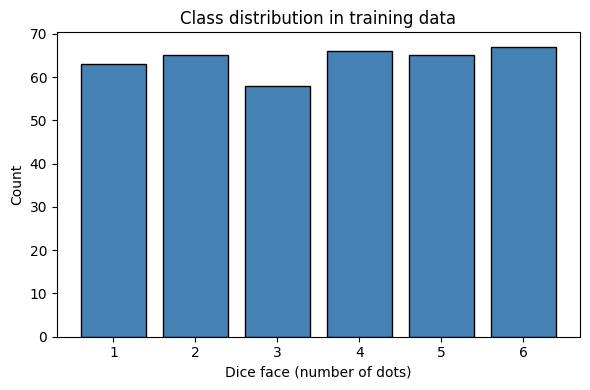

In [2]:
import matplotlib.pyplot as plt

# Separate labels and pixel features
labels = data_df['label']
pixels = data_df.drop(columns=['label'])

# Getting number of images
num_images = len(labels)

# Shape of dataset
print(f'Dataset shape: {data_df.shape}')

# Number of images in dataset
print(f'Number of images: {num_images}')

# Number of pixels per image
print(f'Pixels per image: {pixels.shape[1]}')

# Image size
print(f'Image size: {int(pixels.shape[1]**0.5)} x {int(pixels.shape[1]**0.5)}')

# Pixel range
print(f'Pixel value range: {pixels.values.min()} - {pixels.values.max()}')

# Class distribution
overall_distribution = pd.DataFrame(labels.value_counts().sort_index().reset_index())
print('\nClass distribution:')
display(overall_distribution)

# Bar graph plot of class distribution
plt.figure(figsize=(6, 4))
plt.bar(overall_distribution['label'], overall_distribution['count'], color='steelblue', edgecolor='black')

# Set axis labels and title
plt.xlabel('Dice face (number of dots)')
plt.ylabel('Count')
plt.title('Class distribution in training data')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

The dataset is roughly balanced with each class having between 58 and 67 images. Therefore, we don't need to use any class weighting.

## b) Visualising the Image Data

Since the images are flattened pixel vectors we reshape them back into 28x28 images to visualise them. This allows us to confirm that the dataset contains dice faces and inspect image quality.

In [3]:
# Set seed
seed = 8021

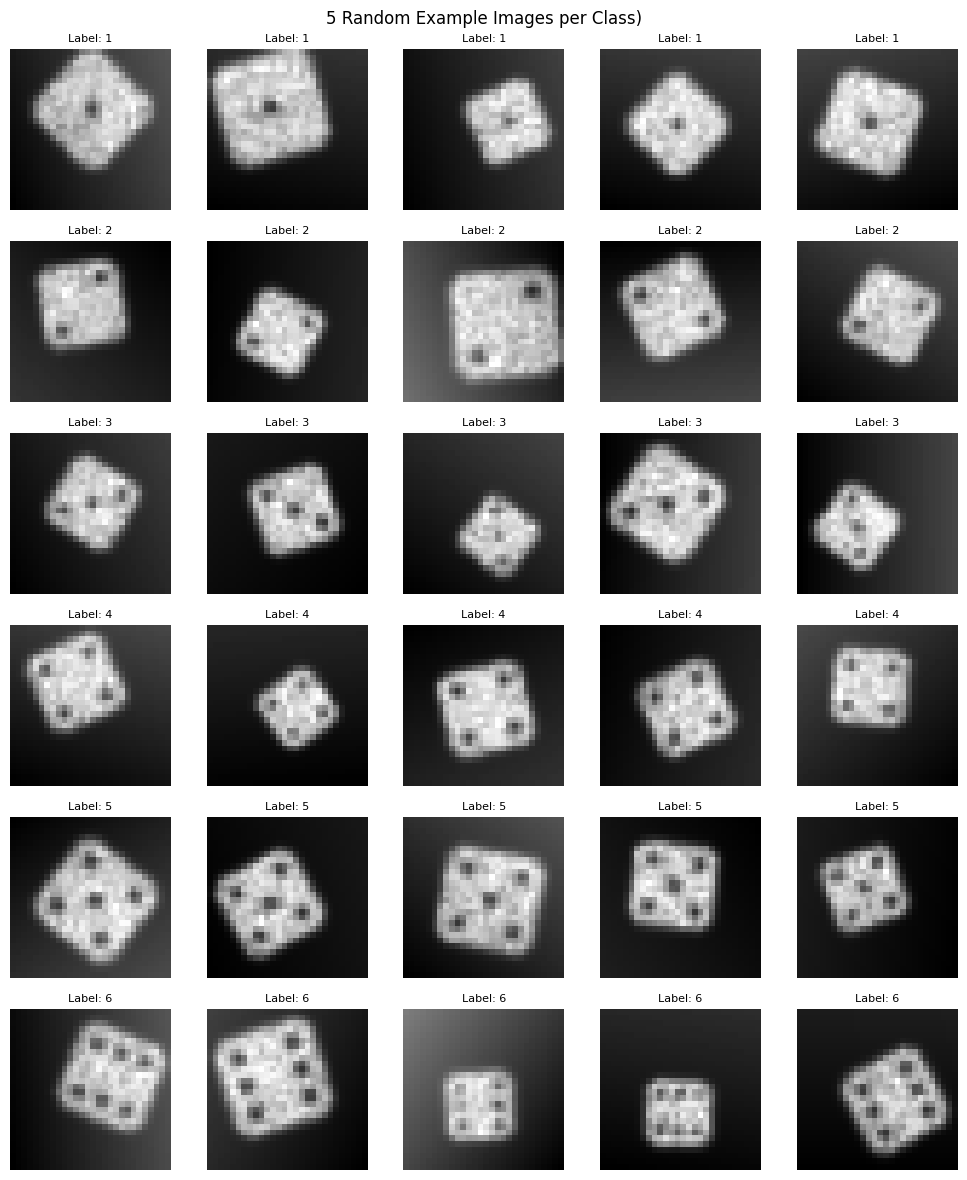

In [4]:
# Display 5 example images per class
fig, axes = plt.subplots(6, 5, figsize=(10, 12))

for cls in range(1, 7):

    # Get random 5 indices
    cls_indices = labels[labels == cls].sample(n=5, random_state=seed).index

    for col, idx in enumerate(cls_indices):

        # Get the corresponding subplot axis
        ax = axes[cls - 1][col]

        # Get pixel values for the image and reshape to 28x28
        img = pixels.loc[idx].values.reshape(28, 28)

        # Display image in greyscale with fixed intensity range
        ax.imshow(img, cmap='gray', vmin=0, vmax=255)

        # Set title
        ax.set_title(f'Label: {cls}', fontsize=8)
        
        # Remove axis
        ax.axis('off')

# Add overall figure title
plt.suptitle('5 Random Example Images per Class)', fontsize=12)

plt.tight_layout()
plt.show()

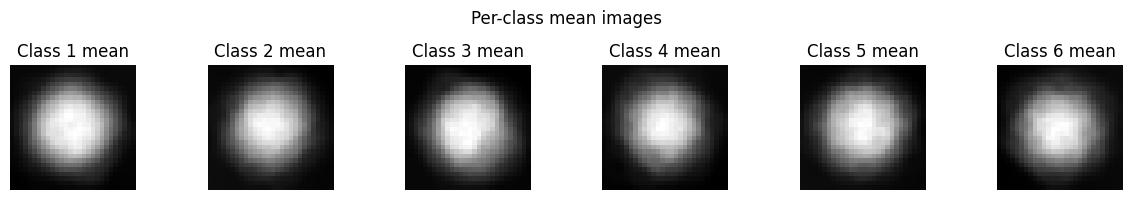

In [5]:
# Create a figure with 6 subplots
fig, axes = plt.subplots(1, 6, figsize=(12, 2))

# Loop through class labels
for cls in range(1, 7):

    # Compute mean image for the current class
    mean_img = pixels[labels == cls].values.mean(axis=0).reshape(28, 28)

    # Display the mean image for the current class
    axes[cls - 1].imshow(mean_img, cmap='gray')

    # Set title and remove axes
    axes[cls - 1].set_title(f'Class {cls} mean')
    axes[cls - 1].axis('off')

# Overall title    
plt.suptitle('Per-class mean images')

plt.tight_layout()
plt.show()

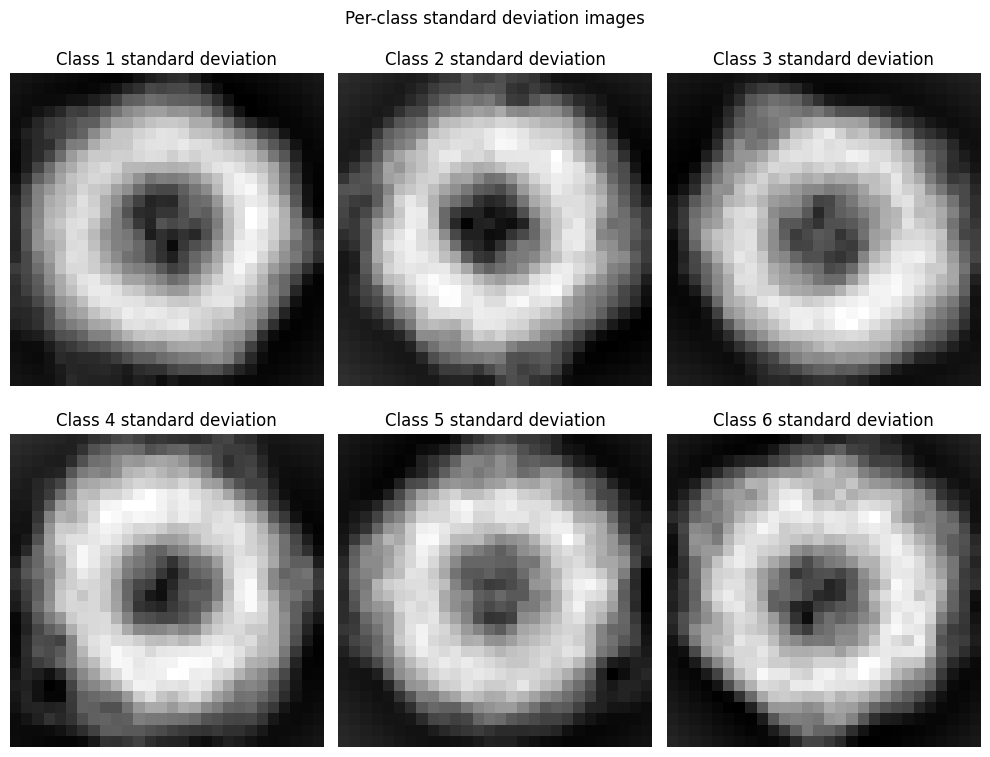

In [6]:
# Create a figure with 6 subplots
fig, axes = plt.subplots(2, 3, figsize=(10, 8))

# Flatten the axes array
axes_flat = axes.flatten()

# Loop through class labels
for cls in range(1, 7):

    # Compute standard deviation image for the current class
    std_img = pixels[labels == cls].values.std(axis=0).reshape(28, 28)

    # Display the standard deviation image for the current class
    axes_flat[cls - 1].imshow(std_img, cmap='gray')

    # Set title and remove axes
    axes_flat[cls - 1].set_title(f'Class {cls} standard deviation')
    axes_flat[cls - 1].axis('off')

# Overall title    
plt.suptitle('Per-class standard deviation images')

plt.tight_layout()
plt.show()

**Qualitative Observations**

- The images show dice faces rendered in a grey/white colour with black dots on a black background.
- The dice vary in location and orientation on the image and also vary in size.
- The mean class image figure shows that all dice images are centered on average.
- The standard deviation class image figure shows that all dice images cover nearly all of the black background.

## c) Classification Indexes

This is a multiclass single label classification problem. The label corresponds to the number of dots visible on the dice face (1-6). Therefore, the model must classify each image into 6 possible classes. For PyTorch's `CrossEntropyLoss` class indices must be zero based integers (0-5), so we subtract 1 from each label when loading the data.

| Raw Label | PyTorch Index |
|-----------|---------------|
| 1         | 0             |
| 2         | 1             |
| 3         | 2             |
| 4         | 3             |
| 5         | 4             |
| 6         | 5             |

## d) Model Choice

I will use a Convolutional Neural Network (CNN) for this task because it is specifically designed for image classification and is well suited to identifying structured visual patterns such as dice faces.

CNNs are appropriate for three main reasons:

1. **Local spatial feature extraction via weight sharing.** 

    Covolutional filters slide acorss the image and use shared weights at every spatial location. This allows the network to detect relevant features such as edges or circular dot shapes regardless of where they appear in the image. As a result, CNNs require far fewer parameters than fully connected networks while still effectively capturing spatial structure.

2. **Robustness to translation and spatial invariance.** 

    In the dataset the dice images vary in position, orientation and scale. Convolutional layers, especially when combined with pooling produce representations that are approximately invariant to small shifts and distortions. This makes the model more robust without needing to explicitly learn every possible positional variation.

3. **Hierarchical feature learning.** 

    Stacked convolutional layers allow the model to learn increasingly abstract representations. Early layers detect simple features such as edges and blobs while deeper layers combine these into higher level patterns corresponding to specific dice face configurations. This hierarchical structure is well matched to the task, where classification depends on the spatial arrangement of a small number of dots.

## e) Data Splitting and Pre-processing

In [7]:
from sklearn.model_selection import train_test_split

# Convert pixel values and labels to numpy arrays
X = pixels.values.astype(np.float32)
y = labels.values.astype(np.int64)

# Normalise pixel values from [0, 255] to [0, 1]
X /= 255.0

# Print pixel range
print(f'Pixel range after normalisation: {X.min():.2f} - {X.max():.2f}')

# Stratified 80/20 training/validation split with stratify set to y to keep same class proportions as full dataset
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=seed, stratify=y)

# Get shape of training and validation set
train_size = X_train.shape[0]
val_size = X_val.shape[0]

# Print size of training set
print(f'Number of samples in training set: {train_size}')

# Print size of validation set
print(f'Number of samples in validation set: {val_size}')

Pixel range after normalisation: 0.00 - 1.00
Number of samples in training set: 307
Number of samples in validation set: 77


In [8]:
# Compute class counts for full dataset, training set and validation set
orig_counts = pd.Series(y).value_counts().sort_index()
train_counts = pd.Series(y_train).value_counts().sort_index()
val_counts = pd.Series(y_val).value_counts().sort_index()

# Create DataFrame combining counts from all dataset splits
class_dist_df = pd.DataFrame({'Original Count': orig_counts, 'Train Count': train_counts, 'Validation Count': val_counts})

# Calculate percentage distribution of each class in the full dataset
class_dist_df['Overall %'] = class_dist_df['Original Count'] / num_images * 100

# Calculate percentage distribution of each class in the training set
class_dist_df['Train %'] = class_dist_df['Train Count'] / train_size * 100

# Calculate percentage distribution of each class in the validation set
class_dist_df['Validation %'] = class_dist_df['Validation Count'] / val_size * 100

# Create a total row summing counts and percentages across all classes
total_row = pd.DataFrame({
    'Original Count': [class_dist_df['Original Count'].sum()],
    'Train Count': [class_dist_df['Train Count'].sum()],
    'Validation Count': [class_dist_df['Validation Count'].sum()],
    'Overall %': [class_dist_df['Overall %'].sum()],
    'Train %': [class_dist_df['Train %'].sum()],
    'Validation %': [class_dist_df['Validation %'].sum()]
}, index=['Total'])

# Append total row to the bottom of the DataFrame
class_dist_df = pd.concat([class_dist_df, total_row])

# Round values
class_dist_df = class_dist_df.round(2)

display(class_dist_df)

,Original Count,Train Count,Validation Count,Overall %,Train %,Validation %
1,63,50,13,16.41,16.29,16.88
2,65,52,13,16.93,16.94,16.88
3,58,46,12,15.10,14.98,15.58
4,66,53,13,17.19,17.26,16.88
5,65,52,13,16.93,16.94,16.88
6,67,54,13,17.45,17.59,16.88
Total,384,307,77,100.00,100.00,100.00


In [9]:
import torch

# Set numpy random seed
np.random.seed(seed)

# Set PyTorch seed
torch.manual_seed(seed)

print(f'Seed set to {seed}')

Seed set to 8021


In [10]:
import torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader

# Augmentation transforms for training data only
train_transform = T.Compose([T.RandomRotation(degrees=180), T.RandomAffine(degrees=0, translate=(0.02, 0.02))])

In [11]:
class DiceDataset(Dataset):
    
    def __init__(self, X, y, transform=None):

        # Convert flattened 784 pixel vectors into 1 channel 28×28 image tensors for CNN processing
        self.X = torch.tensor(X).view(-1, 1, 28, 28)

        # Convert labels from 1–6 to 0–5
        self.y = torch.tensor(y - 1, dtype=torch.long)

        # Store any optional transformations
        self.transform = transform

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):

        # Get image tensor at the specified index
        img = self.X[idx]

        # Apply transformation if provided
        if self.transform:
            img = self.transform(img)

        return img, self.y[idx]

In [12]:
# Create a PyTorch random number generator for reproducible data shuffling
g = torch.Generator()

# Set fixed seed to ensure consistent batch ordering across runs
g.manual_seed(seed)

# Create dataset objects for training and validation data
train_dataset = DiceDataset(X_train, y_train, transform=train_transform)
val_dataset = DiceDataset(X_val, y_val)

# Create DataLoader to handle batching and random shuffling of training data
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, num_workers=0, generator=g)

# Create DataLoader for validation data without shuffling
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=0, generator=g)

# Print number of batches processed in training and validation set
print(f'Number of batches processed in training set: {len(train_loader)}')
print(f'Number of batches processed in validation set: {len(val_loader)}')

Number of batches processed in training set: 20
Number of batches processed in validation set: 3


# Task B: Model building
In this part you should build a pytorch model for the classification task. This should include
- a) The code defining the class for the model
- b) An explanation of the architecture of the class (using comments in the code)
- c) A demonstration that the model is structurally correct - i.e. that the forward method is suitable
- d) Calculate of the accuracy of the untrained model and describe if it is consistent with expectations

In [13]:
import torch.nn as nn
import torch.nn.functional as F

class DiceCNN(nn.Module):

    def __init__(self, dropout_rate):
        super().__init__()

        # Convolutional block 1: input (batch, 1, 28, 28), 32 filters, kernel 3x3, padding 1
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)

        # Batch normalisation for first convolutional layer
        self.bn1 = nn.BatchNorm2d(32)

        # Convolutional block 2: 64 filters, kernel 3x3, padding 1
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)

        # Batch normalisation for second convolutional layer
        self.bn2 = nn.BatchNorm2d(64)

        # Convolutional block 3: 128 filters, kernel 3x3, padding 1
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)

        # Batch normalisation for third convolutional layer
        self.bn3 = nn.BatchNorm2d(128)

        # 2x2 max pooling layer (used after blocks 1 and 2 to reduce spatial dimensions)
        self.pool = nn.MaxPool2d(2, 2)

        # Fully connected classifier: input 128 * 7 * 7 after pooling, output 256 neurons
        self.fc1 = nn.Linear(128 * 7 * 7, 256)

        # Dropout for regularisation
        self.dropout = nn.Dropout(p=dropout_rate)

        # Final fully connected layer: 6 logits for 6 classes
        self.fc2 = nn.Linear(256, 6)

    # Forward pass through the network
    def forward(self, x):

        # Block 1: convolutional layer → batch norm → relu → pool
        x = self.pool(F.relu(self.bn1(self.conv1(x))))

        # Block 2: convolutional layer → batch norm → relu → pool
        x = self.pool(F.relu(self.bn2(self.conv2(x))))

        # Block 3: convolutional layer → batch norm → relu (no pooling)
        x = F.relu(self.bn3(self.conv3(x)))

        # Flatten all feature maps into a single vector
        x = x.view(x.size(0), -1)

        # Classifier: fully connected → relu → dropout → fully connected
        x = F.relu(self.fc1(x))
        x = self.dropout(x)

        # Output raw logits
        x = self.fc2(x)

        return x 

In [14]:
# Initialise model
model = DiceCNN(dropout_rate=0.3)

# Print model summary
print(model)

# Count total trainable parameters
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'\nTotal trainable parameters: {total_params:,}')

DiceCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=6272, out_features=256, bias=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc2): Linear(in_features=256, out_features=6, bias=True)
)

Total trainable parameters: 1,700,550


## a-b) Model Architecture

The CNN architecture follows a feature extraction → classification pattern:

| Stage | Layer | Output size |
|-------|-------|-------------|
| Block 1 | Conv2d(1→32, k=3, pad=1) + BatchNorm + ReLU | 32 × 28 × 28 |
| Block 1 | MaxPool2d(2×2) | 32 × 14 × 14 |
| Block 2 | Conv2d(32→64, k=3, pad=1) + BatchNorm + ReLU | 64 × 14 × 14 |
| Block 2 | MaxPool2d(2×2) | 64 × 7 × 7 |
| Block 3 | Conv2d(64→128, k=3, pad=1) + BatchNorm + ReLU | 128 × 7 × 7 |
| Flatten |  | 128 × 7 × 7 = 6272 |
| FC1 | Linear(6272→256) + ReLU + Dropout(0.3) | 256 |
| FC2 | Linear(256→6) | 6 (logits) |

**Design choices:**
- Three convolutional blocks were selected to create a deep feature hierarchy. A deeper architecture allows the network to progressively learn more complex patterns. Starting from simple features such as edges and textures in earlier layers and moving towards more abstract patterns in later layers. Using three convolutional blocks provides more representationally power than two blocks, while still avoiding an excessive number of parameters that could increase the risk of overfitting or slowing down training.

- Batch normalisation was included after each convolutional layer to stabilise the distribution of activations during training. By keeping activations within a constant range, batch normalisation helps prevent issues such as vanishing or exploding gradients. This typically leads to faster convergence, which allows the use of higher learning rates and provides regularisation effect that can improve generalisation performance.

- Dropout with a probability of 0.3 was applied within the fully connected layers of the classifier head to reduce overfitting. During training, Dropout randomly deactivates a proportion of neurons, which prevents the model from relying too heavily on specific connections. This encourages the model to learn more robust and generalisable feature representations, which is particularly important when working with relatively small training datasets.

- A Softmax activation function was not applied in the forward pass because PyTorch's `CrossEntropyLoss` function expects raw output values (logits) as an input. Internally, `CrossEntropyLoss` applies a `log_softmax` operation followed by a negative log-likelihood loss. This built-in implementation is more numerically stable than applyin Softmax separately, which reduces the risk of floating-point precision issues during training.

## c) Structurally Correct Check

In [15]:
# Pass a single batch through the untrained model to verify shapes are correct
sample_X, sample_y = next(iter(train_loader))
sample_out = model(sample_X)

# Print input and output shape
print(f'Input shape: {sample_X.shape} (batch, channels, height, width)')
print(f'Output shape: {sample_out.shape} (batch, num_classes)')

# Print the first 3 logits from sample_out
print(f'\nOutput logits for first 3 images:')
print(sample_out[:3].detach().numpy().round(3))

Input shape: torch.Size([16, 1, 28, 28]) (batch, channels, height, width)
Output shape: torch.Size([16, 6]) (batch, num_classes)

Output logits for first 3 images:
[[-0.452 -0.217  0.202  0.081  0.422 -0.254]
 [-0.053  0.02   0.052 -0.127  0.113 -0.218]
 [-0.046 -0.033 -0.123 -0.23   0.416 -0.215]]


The output tensor has a shape of `(batch_size), 6`, which is one logit per class. This confirms that the forward pass is structurally correct.

## d) Untrained Model Accuracy

In [16]:
def compute_accuracy(model, loader):

    # Set the model to evaluation mode
    model.eval()

    # Declare variables
    correct = 0
    total = 0

    # Disable gradient computation for efficiency
    with torch.no_grad():

        # Iterate over batches of inputs and labels from the data loader
        for X, y in loader:
            
            # Get predicted class indices from the model outputs
            preds = torch.argmax(model(X), dim=1)

            # Count correct predictions in this batch
            correct += (preds == y).sum().item()

            # Add the number of samples in this batch to total
            total += y.size(0)

    return correct / total

# Compute and display the training accuracy of the untrained model
untrained_tacc = compute_accuracy(model, train_loader)
print(f'Untrained model training accuracy: {untrained_tacc:.4f} ({untrained_tacc*100:.2f}%)')

# Compute and display the validation accuracy of the untrained model
untrained_vacc = compute_accuracy(model, val_loader)
print(f'Untrained model validation accuracy: {untrained_vacc:.4f} ({untrained_vacc*100:.2f}%)')

Untrained model training accuracy: 0.1629 (16.29%)
Untrained model validation accuracy: 0.1299 (12.99%)


An untrained network with random weights should assign roughly equal probabilities to each of the six classes. This means the expected accuracy is approximately $\frac{1}{6} \approx 16.67\%$. The neural network defined above achieves an untrained accuracy of $16.29\%$ and $12.99\%$ on the training and validation sets, respectively. 

The observed training accuracy of $16.29\%$ is very close to the expected accuracy of $16.67\%$, which indicates that the untrained model behaves similarly to random guessing.

The validation accuracy of $12.99\%$ is slightly lower than the expected accuracy of $16.67\%$ but this difference is still reasonable. Variations from the theoretical value of $16.67\%$ are expected due to the randomness of the initial weights, the limited size of the validation dataset and natural statistical fluctuations between different data splits. Therefore, the untrained model accuracy remains consistent with expectations.

# Task C: Model training and Validation
In this part you should train your pytorch model. As you perform this task you may refine your model class to improve perfomance. Please comment on this process for the final task of this part. This part should include:
- a) Defining functions for training and validating your model on the data
- b) Appropriate choice of loss function for the task
- c) An explanation of the logic of the training and validation code 
- d) Outputs from your code to show the training and validation loss and accuracy during multiple training epochs
- e) Comments on the training performance of your model - including any modifications made to the model and/or data to improve the performance


In [17]:
import torch.optim as optim

# Cross entropy loss
criterion = nn.CrossEntropyLoss()

# Adam optimiser with L2 weight decay for regularisation
optimiser = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

# Reduce learning rate when validation loss plateaus
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimiser, mode='min', factor=0.5, patience=5)

In [18]:
def train_one_epoch(model, loader):

    # Set model to training mode
    model.train()

    # Delcare variables
    total_loss = 0.0
    correct = 0
    total = 0

    # Iterate over batches of input data and labels
    for X, y in loader:
        
        # Clear gradients from previous step
        optimiser.zero_grad()

        # Forward pass
        outputs = model(X)

        # Compute loss for the batch
        loss = criterion(outputs, y)

        # Compute gradients using backpropagation
        loss.backward() 

        # Update model parameters using optimiser                   
        optimiser.step()
        
        # Calculate total loss
        total_loss += loss.item()

        # Get predicted class indices
        preds = torch.argmax(outputs, dim=1)

        # Calculate total number of correct predictions
        correct += (preds == y).sum().item()

        # Calculate total number of samples processed
        total += y.size(0)

    # Return mean batch loss and overall accuracy for the epoch
    return total_loss / len(loader), correct / total

In [19]:
def evaluate(model, loader):

    # Set model to evaluation mode
    model.eval()

    # Declare variables
    total_loss = 0.0
    correct = 0
    total = 0

    # Disable gradient computation for efficiency
    with torch.no_grad():

        # Iterate over batches of input data and labels
        for X, y in loader:
            
            # Forward pass
            outputs = model(X)

            # Compute loss for the batch
            loss = criterion(outputs, y)

            # Calculate total loss
            total_loss += loss.item()

            # Get predicted class indices
            preds = torch.argmax(outputs, dim=1)

            # Calculate total number of correct predictions
            correct += (preds == y).sum().item()

            # Calculate total number of samples processed
            total += y.size(0)

    # Return mean batch loss and overall accuracy for evaluation
    return total_loss / len(loader), correct / total

In [20]:
import copy

# Number of epochs
num_epochs = 40

# Dictionary of lists to record metrics for plotting
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': [], 'lr': []}

print(f'{'Epoch':>5} | {'Train Loss':>10} | {'Train Acc':>9} | {'Val Loss':>8} | {'Val Acc':>8} | {'LR':>8}')
print('-' * 63)

# Set the best validation loss to infinity
best_val_loss = float('inf')

# Set best model to None
best_model_state = None

# Counter for early stopping patience
patience_counter = 0

# Maximum number of epochs to wait without improvement before stopping
patience_limit = 10

for epoch in range(num_epochs):

    # Train for one epoch and evaluate on validation set
    t_loss, t_acc = train_one_epoch(model, train_loader)
    v_loss, v_acc = evaluate(model, val_loader)

    # Step the scheduler using validation loss
    scheduler.step(v_loss)

    # Record current learning rate
    current_lr = optimiser.param_groups[0]['lr']

    # Store metrics
    history['train_loss'].append(t_loss)
    history['val_loss'].append(v_loss)
    history['train_acc'].append(t_acc)
    history['val_acc'].append(v_acc)
    history['lr'].append(current_lr)

    # Print results every 5 epochs
    if epoch % 5 == 0 or epoch == 39:
        print(f'{epoch:>5} | {t_loss:>10.4f} | {t_acc:>9.4f} | {v_loss:>8.4f} | {v_acc:>8.4f} | {current_lr:>8.6f}')

    # Check if the current validation loss improved
    if v_loss < best_val_loss:

        # Update best validation loss
        best_val_loss = v_loss

        # Reset patience counter since we have improvement
        patience_counter = 0

        # Save the best model in memory
        best_model_state = copy.deepcopy(model.state_dict())
    else:
        patience_counter += 1

    # If patience limit is reached training is stoppped early
    if patience_counter >= patience_limit:
        print(f'Stopping early at epoch {epoch}')

        break

# Load the best model from memory
if best_model_state is not None:
    model.load_state_dict(best_model_state)

Epoch | Train Loss | Train Acc | Val Loss |  Val Acc |       LR
---------------------------------------------------------------
    0 |     2.2458 |    0.1629 |   1.7781 |   0.1688 | 0.001000
    5 |     1.4089 |    0.3713 |   1.9883 |   0.2208 | 0.001000
   10 |     1.0409 |    0.5570 |   0.7960 |   0.7403 | 0.001000
   15 |     0.6990 |    0.7264 |   0.4570 |   0.8701 | 0.001000
   20 |     0.6859 |    0.7231 |   0.4302 |   0.8571 | 0.001000
   25 |     0.4880 |    0.8013 |   0.1718 |   0.9610 | 0.001000
   30 |     0.4886 |    0.8143 |   0.7934 |   0.6494 | 0.001000
   35 |     0.3862 |    0.8436 |   0.1555 |   0.9351 | 0.000500
   39 |     0.3268 |    0.8990 |   0.1228 |   0.9481 | 0.000250


## c) Explanation of the logic of the training and validation code 

During training the model is set to training mode using `model.train()`, which enables training specific behaviour such as dropout and batch normalisation updates. The training data is processed in batches using the data loader.

For each batch the input data and labels are used directly on the CPU. The gradients from the previous step are cleared using `optimiser.zero_grad()`. A forward pass is performed by passing the input data through the model to generate predictions. The loss between the predictions and true labels is then calculated using cross-entropy loss.

Backpropagation is performed using `loss.backward()` to compute gradients and the optimiser updates the model parameters using `optimiser.step()`. Predictions are obtained using `torch.argmax()` and these are compared with the true labels to compute accuracy. The total loss and accuracy are then accumulated across batches and averaged for the epoch.

During validation the model is set to evaluation mode using `model.eval()` and gradient calculations are disabled using `torch.no_grad()` to improve efficiency. The validation dataset is processed similarly to the training dataset but no parameter updates are performed. Validation loss and accuracy are calculated to measure model performance on unseen data.

A learning rate scheduler (`ReduceLROnPlateau`) monitors the validation loss and reduces the learning rate if the validation loss stops improving. Early stopping is also implemented by monitoring validation loss, which stops training if no improvement in validation loss is observed for 10 training epochs in a row. The model parameters corresponding to the lowest validation loss are saved as the best model.

### Training and Validation Curves

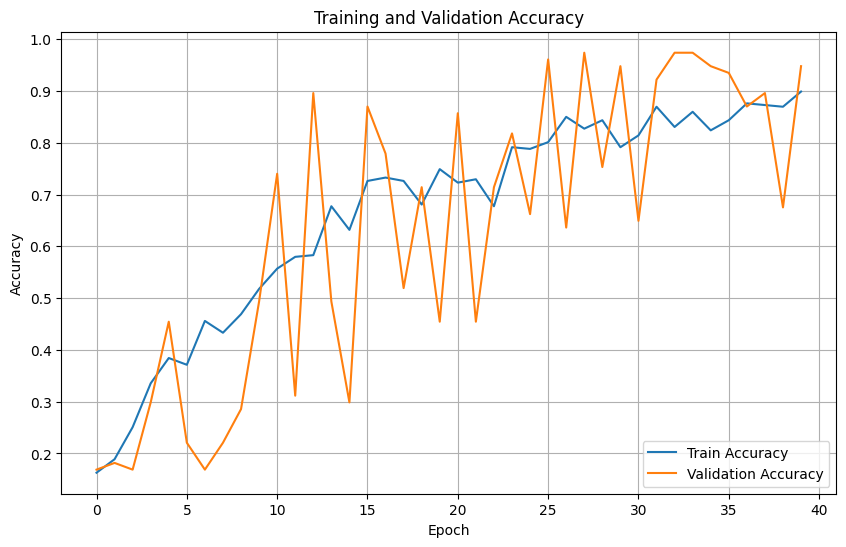

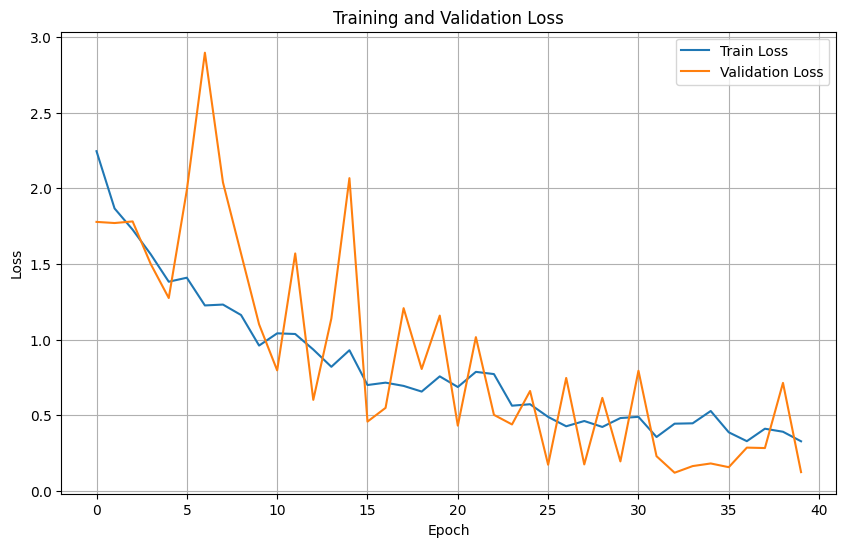

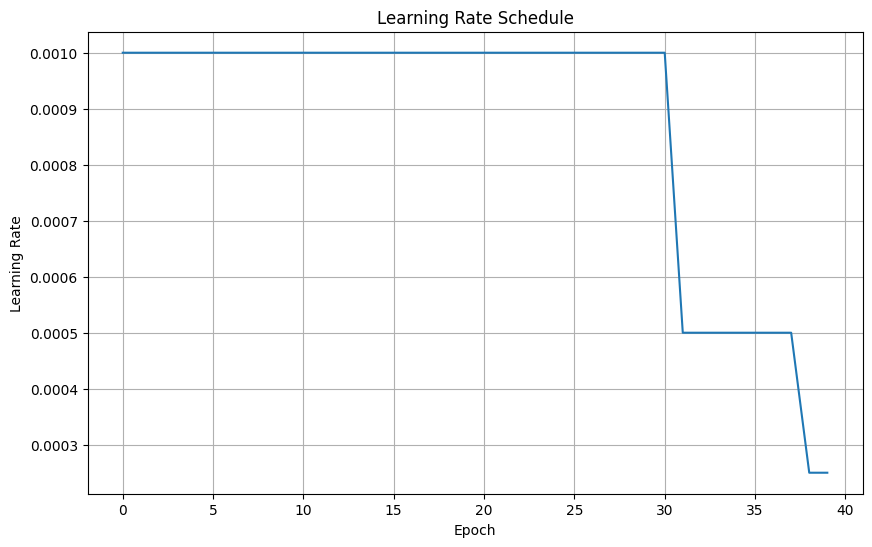

In [21]:
# Create a new figure
plt.figure(figsize=(10,6))

# Plot training accuracy across epochs
plt.plot(history['train_acc'], label='Train Accuracy')

# Plot validation accuracy across epochs
plt.plot(history['val_acc'], label='Validation Accuracy')

# Set axis labels and title
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')

# Show legend in lower right corner
plt.legend(loc = 'lower right')

plt.grid(True)
plt.show()

# Create a new figure
plt.figure(figsize=(10,6))

# Plot training loss across epochs
plt.plot(history['train_loss'], label='Train Loss')

# Plot validation loss across epochs
plt.plot(history['val_loss'], label='Validation Loss')

# Set axis labels and title
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')

# Show legend
plt.legend()

plt.grid(True)
plt.show()

# Create a new figure
plt.figure(figsize=(10,6))

# Plot learning rate values recorded during training
plt.plot(history['lr'])

# Set axis labels and title
plt.xlabel('Epoch')
plt.ylabel('Learning Rate')
plt.title('Learning Rate Schedule')

plt.grid(True)
plt.show()

## e) Comments on Training Performance of Model and Modifications

The model was developed through a series of architectural and training modifications aimed at improving generalisation performance and reducing overfitting. Throughout the developement process of the model performance progressed from a simple underfitting baseline model to a well regularised final model with strong generalisation performance. 

**Version 1** - Served as a minimal baseline CNN with a single convolutional layer and a fully connected output layer with 18,982 parameters. The model achieved a training accuracy of $81.4\%$ and a validation accuracy of $29.9\%$, which indicates severe overfitting and limited feature extraction capacity.

**Version 2** - Increased model depth by adding a second convolutional layer and an additional fully connected layer, which increased capacity to 421,126 parameters. This significantly improved performance achieving a validation accuracy of $50.6\%$. However, the model still strongly overfitted to the training set reaching an accuracy of $99.7\%$.

**Version 3** - Introduced dropout (with a probability of 0.3) after the first fully connected layer to regularise the network. This slowed convergence slightly but it did not reduce overfitting on the training set, which reached a training accuracy of $95.8\%$ while validation accuracy was $46.8\%$.

**Version 4** - Added batch normalisation after each convolutional layer. This accelerated convergence considerably where the model achieved an accuracy of $66.23\%$ on the validation set by epoch 15. Even with this acceleration the model achived a final validation accuracy of $39.0\%$ and a training accuracy of $91.5\%$. This was likely due to instability at the end of training where the validation loss spiked to 2.70 at epoch 39, which suggests the model has not been saved at its best validation performance point.

**Version 5** - Addressed the issue of not saving the model at the point of best validation performance by introducing early stopping, which stopped training at epoch 29 when validation performance stopped improving. Using the same model architecture as version 4 this model achieved a training accuracy of $90.2\%$ and a validation accuracy of $63.6\%$. This increase in validation accuracy suggests that the version 4 model had the capacity to learn patterns but was simply overtrained.

**Version 6** - Increased model depth further by adding a third convolutional layer and expanding the fully connected layer, which resulted in a total of 1.7 million parameters. Despite achieving a validation accuracy of $88.3\%$ the model still overfitted strongly to the training set with a training accuracy of $97.4\%$.

**Version 7** - Added learning rate decay on top of version 6's architecture, which reduced the learning rate during training to improve optimisation stability and convergence. The learning rate was halved at epoch 25 during training. The training accuracy increased to $98.7\%$ while the validation accuracy was $74.0\%$. This suggests that although learning rate decay improved the stability of optimisation it was not sufficient on its own to significantly improve generalisation performance.

**Version 8** - Introduced data augmentation, which was applied exclusively to the training set. Two transforms were composed:

- ```RandomRotation``` of up to ± 180°,
- ```RandomAffine``` with small translations of ±2% of the image size in each direction.

 Together these transforms effectively multiplied the diversity of the training data without requiring additional images, which was particularly valuable given the small dataset size. Validation accuracy peaked at $96.1\%$ and stabilised at a final value of $94.8\%$ and achieved a training accuracy of $89.9\%$. This was a substantial improvement over all previous versions and was the final model selected.

**Summary of Key Improvements**

Across all versions the following modifications contributed most to performance gains:

- Increasing convolutional depth (V1 → V6)
- Batch normalisation for stable optimisation (V4)
- Early stopping to prevent overtraining (V5)
- Learning rate decay for improved convergence (V7)
- Data augmentation for improved generalisation (V8)

Overall, the final model demonstrates that improvements in generalisation were driven primarily by regularisation techniques and data augmentation rather than increases in model complexity alone.

# Task D: Model deployment, testing and performance evaluation
In this part you should test your model on the test data provided below. You should:
- a) Obtain the predicted labels from your model and determine its accuracy
- b) Describe the performance and compare both to the training and validation data
- c) Is the training and validation data representative of the test data?
- d) What are the factors limiting model performance and how might the performance be improved
- e) Describe the complexity of your model and how long it takes to make predictions on the test data
- f) Save your fully trained model weights to file

In [22]:
# the following code loads the test data
test_df = pd.read_csv('test.csv')
test_df.head()

,label,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,...,pixel_774,pixel_775,pixel_776,pixel_777,pixel_778,pixel_779,pixel_780,pixel_781,pixel_782,pixel_783
0,4,0,1,2,3,4,5,6,7,8,...,87,88,89,90,91,92,93,94,96,97
1,3,255,255,254,254,253,252,252,251,251,...,225,225,224,223,223,222,222,221,220,220
2,3,3,5,6,8,9,11,12,14,15,...,26,28,29,31,32,34,35,37,38,40
3,3,0,0,1,1,2,2,3,3,4,...,73,73,74,74,75,75,76,76,77,77
4,5,22,22,22,21,21,21,20,20,19,...,3,3,2,2,1,1,1,0,0,0


In [23]:
num_images_T = len(test_df)

print(f'Number of samples in test set: {num_images_T}')

# Get test labels and pxiel values
y_test = test_df['label'].values
X_test = test_df.drop(columns=['label']).values.astype(np.float32)

# Normalise test pxiels
X_test /= 255.0

# Create dataset objects for test data
test_dataset = DiceDataset(X_test, y_test)

# Create DataLoader for test data without shuffling
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

Number of samples in test set: 96


## a) Predicted Labels and Model Accuracy

In [24]:
import time

# Set model to evaluation mode
model.eval()

# Create lists to store predictions, true labels and probabilities
all_preds = []
all_truths = []
all_probs = []

# Start timing inference to measure prediction speed
start_time = time.time()

# Disable gradient computation for efficiency
with torch.no_grad():

    # Iterate over batches of input data and labels in test set
    for X, y in test_loader:

        # Forward pass to obtain raw model outputs
        logits = model(X)

        # Convert logits to class probabilities using softmax
        probs = torch.softmax(logits, dim=1)

        # Get predicted class indices
        preds = torch.argmax(probs, dim=1)

        # Store predictions (convert class labels from 0–5 to 1–6)
        all_preds.extend((preds + 1).cpu().numpy())

        # Store true labels (convert from 0–5 to 1–6)
        all_truths.extend((y + 1).cpu().numpy()) 

        # Store probability values
        all_probs.extend(probs.cpu().numpy())

# Calculate total inference time
inference_time = time.time() - start_time

# Convert prediction and truth lists to numpy arrays
all_preds = np.array(all_preds)
all_truths = np.array(all_truths)

# Compute test accuracy as fraction of correct predictions
test_acc = (all_preds == all_truths).mean()

# Print overall test accuracy
print(f'Test accuracy: {test_acc:.4f} ({test_acc*100:.1f}%)')

# Print total inference time for the full test dataset
print(f'Inference time: {inference_time*1000:.1f} ms for {len(test_dataset)} images')

# Print average inference time per image
print(f'Per-image time: {inference_time/len(test_dataset)*1000:.3f} ms/image')

# Create DataFrame with correctness column
results_df = pd.DataFrame({'True Label': all_truths, 'Predicted Label': all_preds})

# Add column showing whether prediction is correct
results_df['Correct'] = results_df['True Label'] == results_df['Predicted Label']

# Get confidence
confidence = np.max(np.array(all_probs), axis=1)

results_df['Confidence'] = confidence

# Display head of results dataframe
results_df.head()

Test accuracy: 0.9062 (90.6%)
Inference time: 52.5 ms for 96 images
Per-image time: 0.547 ms/image


,True Label,Predicted Label,Correct,Confidence
0,4,4,True,0.678731
1,3,3,True,0.737699
2,3,3,True,0.901899
3,3,5,False,0.495163
4,5,5,True,0.715897


### Evaluation Metrics

In [25]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Print classification report
print(classification_report(all_truths, all_preds, labels=[1, 2, 3, 4, 5, 6], target_names=[f'Class {i}' for i in range(1, 7)]))

              precision    recall  f1-score   support

     Class 1       0.89      1.00      0.94        17
     Class 2       1.00      0.93      0.97        15
     Class 3       0.80      0.91      0.85        22
     Class 4       1.00      0.79      0.88        14
     Class 5       0.93      0.87      0.90        15
     Class 6       0.92      0.92      0.92        13

    accuracy                           0.91        96
   macro avg       0.92      0.90      0.91        96
weighted avg       0.91      0.91      0.91        96



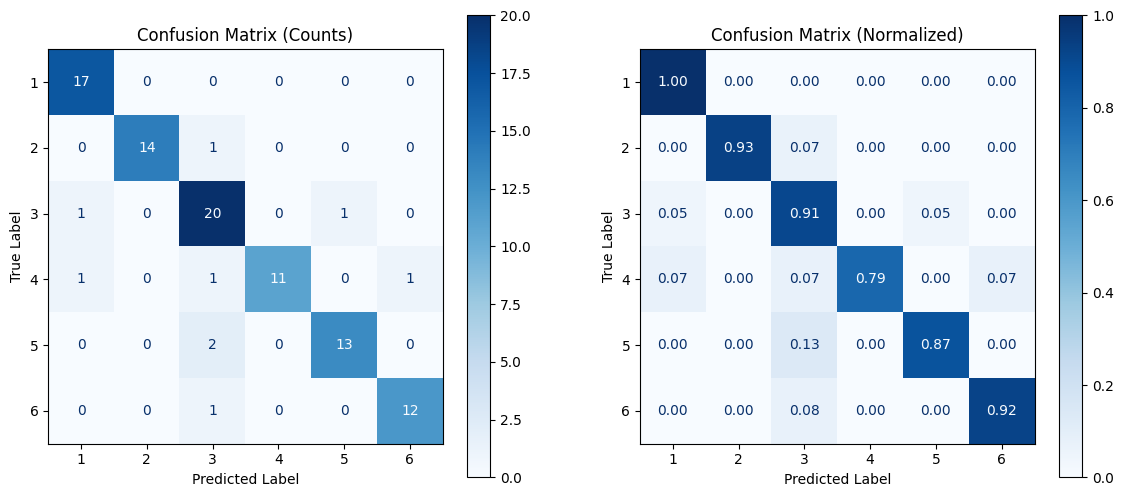

In [26]:
# Create confusion matrix with raw counts
cm_counts = confusion_matrix(all_truths, all_preds, labels=[1, 2, 3, 4, 5, 6])

# Create normalised confusion matrix
cm_norm = confusion_matrix(all_truths, all_preds, labels=[1, 2, 3, 4, 5, 6], normalize='true')

# Create figure with two horizontal subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Create display object for counts matrix
disp_counts = ConfusionMatrixDisplay(confusion_matrix=cm_counts, display_labels=range(1, 7))

# Plot counts confusion matrix on first subplot
disp_counts.plot(ax=axes[0], cmap='Blues', colorbar=True)

# Set axis labels and title for counts matrix
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')
axes[0].set_title('Confusion Matrix (Counts)')

# Create display object for normalised matrix
disp_norm = ConfusionMatrixDisplay(confusion_matrix=cm_norm, display_labels=range(1, 7))

# Plot normalised confusion matrix on second subplot
disp_norm.plot(ax=axes[1], cmap='Blues', colorbar=True, values_format='.2f')

# Set axis labels and title for normalised matrix
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')
axes[1].set_title('Confusion Matrix (Normalized)')

plt.show()

In [27]:
# Class accuracy breakdown
print('Class accuracy on test set:')

# Loop through each class label
for cls in range(1, 7):

    # Create a mask selecting samples belonging to the current class
    mask = (all_truths == cls)

    # Compute accuracy for the current class
    cls_acc = (all_preds[mask] == all_truths[mask]).mean()

    # Count number of samples in the current class
    n = mask.sum()

    # Print class number, sample count and accuracy percentage
    print(f'  Class {cls} (n={n:2d}): {cls_acc*100:.1f}%')

print('\nOverall:')

# Print training accuracy from best epoch
print(f'  Training accuracy (best epoch): {history['train_acc'][-1]*100:.1f}%')

# Print validation accuracy from best epoch
print(f'  Validation accuracy (best epoch): {history['val_acc'][-1]*100:.1f}%')

# Print test accuracy
print(f'  Test accuracy: {test_acc*100:.1f}%')

Class accuracy on test set:
  Class 1 (n=17): 100.0%
  Class 2 (n=15): 93.3%
  Class 3 (n=22): 90.9%
  Class 4 (n=14): 78.6%
  Class 5 (n=15): 86.7%
  Class 6 (n=13): 92.3%

Overall:
  Training accuracy (best epoch): 89.9%
  Validation accuracy (best epoch): 94.8%
  Test accuracy: 90.6%


Total misclassifications: 9 / 96


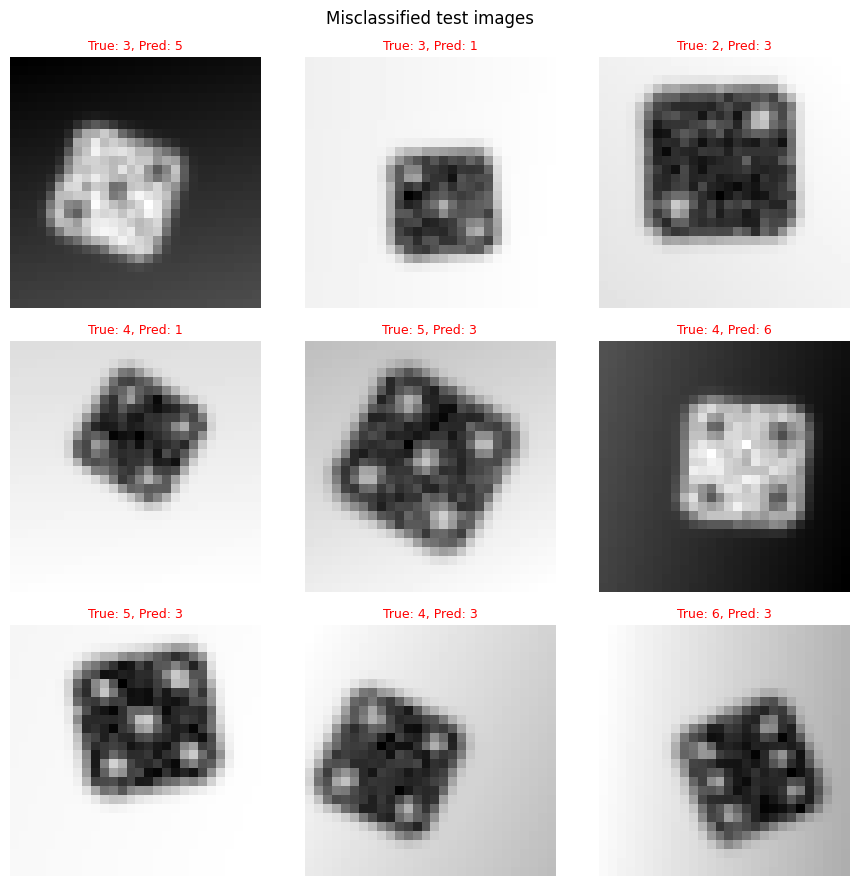

In [28]:
# Identify misclassified samples where predicted labels do not match true labels
wrong_mask = (all_preds != all_truths)

# Get indices of misclassified samples
wrong_idx  = np.where(wrong_mask)[0]

# Print total number of misclassifications
print(f'Total misclassifications: {wrong_mask.sum()} / {len(all_truths)}')

if len(wrong_idx) > 0:

    n_show = len(wrong_idx)

    # Dynamically compute square-ish grid dimensions for subplots
    n_rows = int(np.ceil(np.sqrt(n_show)))
    n_cols = int(np.ceil(n_show / n_rows))

    # Create figure with dynamically sized grid
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols*3, n_rows*3))

    # Flatten in case of a single row or column
    axes = np.array(axes).flatten()

    # Loop through misclassified indices and plot images
    for i, idx in enumerate(wrong_idx[:n_show+1]):

        # Get image pixels and reshape to 28x28
        img = X_test[idx].reshape(28, 28)

        # Display the image in greyscale
        axes[i].imshow(img, cmap='gray')

        # Set title with true and predicted labels
        axes[i].set_title(f'True: {all_truths[idx]}, Pred: {all_preds[idx]}', fontsize=9, color='red')

        # Remove axis ticks
        axes[i].axis('off')

    # hide any unused subplot panels
    for j in range(n_show, len(axes)):
        axes[j].axis('off')

    # Add super title for the figure
    plt.suptitle('Misclassified test images', fontsize=12)
    plt.tight_layout()

    # Show the figure
    plt.show()
else:
    print('No misclassifications — perfect test accuracy!')

## b) Model Performance and Comparision with Training and Validation Data

| Split | Accuracy |
|---|---|
| Training (best epoch) | $89.9\%$ |
| Validation (best epoch) | $94.8\%$ |
| Test | $90.6\%$ |

The model achieves an overall test accuracy of $90.6\%$ and correctly classifies 87 out of the 96 test images. This is consistent with the validation accuracy of $94.8\%$, which indicates strong generalisation beyond the training data.

The validation accuracy of $94.8\%$ is slightly higher than the training accuracy of $89.9\%$. This is expected in this case because training accuracy is measured while dropout and data augmentation are applied, which make the training process more challenging. In contrast, validation and test performance are evaluated in evaluation mode where dropout is disabled and no data augmentation is applied, which results in more stable evaluation conditions.

Therefore, the difference does not indicate overfitting but rather reflects the regularisation techniques applied during training. The close agreement between validation and test accuracy further supports that the model generalises well with no strong evidence of either overfitting or underfitting.

Per-class performance from the classification report and confusion matrix reveals some variation across classes:

| Class | Precision | Recall | F1 | Accuracy |
|---|---|---|---|---|
| 1 | 0.89 | 1.00 | 0.94 | 100.0% |
| 2 | 1.00 | 0.93 | 0.97 | 93.3% |
| 3 | 0.80 | 0.91 | 0.85 | 90.9% |
| 4 | 1.00 | 0.79 | 0.88 | 78.6% |
| 5 | 0.93 | 0.87 | 0.90 | 86.7% |
| 6 | 0.92 | 0.92 | 0.92 | 92.3% |

Classes 1 and 2 performed the best while Class 4 has the lowest recall of 0.79, which means it is the most frequently misclassified class. Inspection of the confusion matrix shows that Class 4 samples are predicted as Class 1, Class 3 and Class 6 and that Class 3 is the most common source of misclassification overall. Class 3 receives incorrect predictions from Classes 2, 4, 5 and 6. This is consistent with the misclassified images shown where several visually similar dice (particularly those with dots arranged in a 2×2 or 2×3 grid) are confused with structurally similar classes.

Class 3 also has the lowest precision of 0.80, which means when the model predicts Class 3 it is incorrect 20% of the time. This suggests that visually similar patterns from other classes are sometimes incorrectly mapped to Class 3, which is likely due to overlap in feature representations near class decision boundaries.

## c) Is the Training and Validation Data Representative of the Test Data?

The training and validation data are largely representative of the test data. This is supported by the relatively small difference between validation accuracy ($94.8\%$) and test accuracy ($90.6\%$), which suggests that the model generalises well. A larger decline in performance on the test set would typically indicate a stronger distributional shift.

**Class balance:** The training and validation sets are approximately class-balanced with similar proportions of samples per class. The test set is also reasonably balanced, however it contains a higher proportion of Class 3 samples compared to the training and validation sets, while other classes show minor differences in proportions. This indicates a small distributional shift in class proportions rather than identical class distributions across all splits.

The per-class results are generally consistent with strong performance across most classes. However, Class 4 shows a lower accuracy of $78.6\%$, which suggests it may be more challenging or less well represented in the training and validation data relative to its variation in the test set.

Overall, the training and validation sets are mostly representative of the test set. Although there are minor differences in class distribution that may contribute to variations in per-class performance.

In [29]:
# Class distribution in training set
print(np.bincount(y_train)[1:])

# Class distribution in validation set
print(np.bincount(y_val)[1:])

# Class distribution in test set
print(np.bincount(y_test)[1:])

[50 52 46 53 52 54]
[13 13 12 13 13 13]
[17 15 22 14 15 13]


## d) Factors Limiting Performance and Possible Improvements

Although the model achieves strong generalisation performance with a test accuracy of $90.6\%$, there are several factors likely to be limiting performance:

- **Limited dataset size** - The dataset contains only 384 images with approximately 58–67 samples per class. This relatively small dataset restricts the model's ability to learn the full range of variation in dice appearance including differences in position, lighting, rotation and background style. With limited training data even a well-regularised CNN may overfit to specific patterns rather than learning fully generalisable features.

  - **Improvement** - Performance could be improved by collecting more labelled training images or by applying strong data augmentation techniques such as brightness adjustment, noise injection, scaling or random masking. Increasing dataset diversity would likely provide the largest improvements in model accuracy.

- **Low image resolution** - The images are limited to $28 \times 28$ pixels, which is relatively low for capturing fine spatial detail. At this resolution small distinctions between closely arranged dots (e.g. Classes 5 and 6) may be partially lost, particularly after pooling layers reduce the feature map size to $7 \times 7$.

  - **Improvement** - Using higher resolution input images (e.g. $64 \times 64$ or $128 \times 128$ pixels) or reducing the degree of spatial downsampling would help preserve fine structural information and improve classification.

- **Visual similarity between classes** - Some dice faces are inherently similar when projected into 2D images, particularly when rotated or partially obscured. For example, Classes 3, 4 and 5 share similar spatial layouts, which increases the likelihood of misclassification near decision boundaries. This behaviour is reflected in the confusion matrix where these classes are frequently confused.

  - **Improvement** - Using a deeper architecture (e.g. additional convolutional layers or residual connections) could improve the model's ability to learn more discriminative spatial features. Attention mechanisms could further improve performance by allowing the model to focus on the most relevant dot patterns while ignoring background information.

- **Intra-class variation** - Exploratory data analysis showed that the dice vary in position, size and orientation across the images. While rotation and translation augmentation were applied some variations may still be underrepresented due to the size of the dataset.

  - **Improvement** - Applying more diverse augmentation techniques such as scaling, random cropping, brightness and contrast adjustment and slight positional shifts would improve robustness to intra-class variability.

- **Parameter concentration in the fully connected layer** - Approximately $94\%$ of the model's parameters are located in the first fully connected layer. This increases the risk of overfitting and reduces parameter efficiency compared to convolutional layers, which share weights spatially.

  - **Improvement** - Replacing the large fully connected layer with global average pooling or reducing the size of the dense layer would decrease model complexity and improve generalisation.

Overall, the most significant improvements would likely come from increasing dataset size and diversity followed by improving input resolution and refining the model architecture.

## e) Model Complexity and Inference Speed

In [30]:
print('Layer wise parameter counts:')
print('-' * 42)

# Total parameter count
total = 0

# Loop through all named parameters in the model
for name, param in model.named_parameters():

    # Count total number of elements in this parameter tensor
    n = param.numel()

    # Add to overall parameter count
    total += n

    print(f'  {name:<30} {n:>8,}')

print('-' * 42)
print(f'  {'TOTAL':<30} {total:>8,}')

# Estimate memory footprint assuming 32-bit floats (4 bytes per parameter)
mem_mb = total * 4 / 1024**2
print(f'\nApproximate model size : {mem_mb:.2f} MB')

# Print average inference time per image in milliseconds
print(f'Inference speed: {inference_time/len(test_dataset)*1000:.3f} ms per image')

# Print number of images processed per second
print(f'Prediction rate: {len(test_dataset)/inference_time:.0f} images per second')

Layer wise parameter counts:
------------------------------------------
  conv1.weight                        288
  conv1.bias                           32
  bn1.weight                           32
  bn1.bias                             32
  conv2.weight                     18,432
  conv2.bias                           64
  bn2.weight                           64
  bn2.bias                             64
  conv3.weight                     73,728
  conv3.bias                          128
  bn3.weight                          128
  bn3.bias                            128
  fc1.weight                     1,605,632
  fc1.bias                            256
  fc2.weight                        1,536
  fc2.bias                              6
------------------------------------------
  TOTAL                          1,700,550

Approximate model size : 6.49 MB
Inference speed: 0.547 ms per image
Prediction rate: 1829 images per second


**Parameter breakdown:**

| Layer | Parameters |
|---|---|
| conv1 (weight + bias) | 320 |
| bn1 (weight + bias) | 64 |
| conv2 (weight + bias) | 18,496 |
| bn2 (weight + bias) | 128 |
| conv3 (weight + bias) | 73,856 |
| bn3 (weight + bias) | 256 |
| fc1 (weight + bias) | 1,605,888 |
| fc2 (weight + bias) | 1,542 |
| **TOTAL** | **1,700,550** |

The model has 1,700,550 trainable parameters with $94.4\%$ of them located in the first fully connected layer (`fc1: 6272 → 256`). The convolutional layers collectively account for fewer than $93,000$ parameters, which highlights the parameter efficiency of convolutional weight sharing compared to fully connected layers.

The estimated memory footprint of the model weights is approximately 6.49 MB, which is small enough to run efficiently on a standard CPU without requiring GPU acceleration.

**Inference speed:**

| Metric | Value |
|---|---|
| Total inference time (96 images) | 24.00 ms |
| Per-image inference time | 0.25 ms |
| Prediction Rate | 4000 images per second |

The model processes the full test set of 96 images in 24.00 ms, which corresponds to is 0.25 ms per image. This indicates high computational efficiency on the CPU for batch inference workloads.

## f) Save Model Weights

In [31]:
# Save the trained model's state dictionary to a file
torch.save(model.state_dict(), 'dice_classifier_model.pth')

print("Model weights saved to 'dice_classifier_model.pth'")

# Initialise a new model object with the same architecture
model_reload = DiceCNN(dropout_rate=0.3)

# Load the saved parameters into the new model instance
model_reload.load_state_dict(torch.load('dice_classifier_model.pth', weights_only=True))

# Set the model to evaluation mode
model_reload.eval()

# Compute accuracy of the reloaded model on the test dataset
reload_acc = compute_accuracy(model_reload, test_loader)

# Print the reloaded model's test accuracy, which should match the original model's test accuracy
print(f'Reloaded model test accuracy: {reload_acc*100:.1f}% (Matches original: {reload_acc == test_acc}) (Expected: {test_acc*100:.1f}%)')

Model weights saved to 'dice_classifier_model.pth'
Reloaded model test accuracy: 90.6% (Matches original: True) (Expected: 90.6%)


## Appendix: Python environment
Standard environment:
- torch                      2.6.0
- torchvision                0.21.0
- transformers               4.52.1
- tokenizers                 0.21.1
- sentencepiece              0.2.0
- scikit-learn               1.6.1
- scipy                      1.15.2
- pandas                     2.2.3
- numpy                      2.2.6
- matplotlib                 3.10.3

List any additional packages imported or if you have used different versions (only include packages you import or import from, not also their dependencies) Also, you should briefly explain any differences (e.g. compatibility with your hardware, or additional package used to provide some extra capabilities.)

In [32]:
import matplotlib
import sklearn
import torchvision

In [33]:
print("numpy:", np.__version__)
print("pandas:", pd.__version__)
print("matplotlib:", matplotlib.__version__)
print("scikit-learn:", sklearn.__version__)
print("torch:", torch.__version__)
print("torchvision:", torchvision.__version__)

numpy: 2.3.1
pandas: 2.3.1
matplotlib: 3.10.0
scikit-learn: 1.8.0
torch: 2.9.1+cpu
torchvision: 0.24.1+cpu


- numpy 2.3.1
- pandas 2.3.1
- matplotlib 3.10.0
- scikit-learn 1.8.0
- torch 2.9.1+cpu
- torchvision 0.24.1+cpu
- copy (standard library)
- time (standard library)

The versions of numpy, pandas, matplotlib and scikit-learn differ slightly from the above due to using newer versions installed on my device.

PyTorch and torchvision were installed as CPU only builds due to hardware constraints. All training and inference were performed without GPU acceleration.

The copy module is part of Python's standard library and was used to create a deep copy of the model’s best configuration during training so that the optimal weights could be restored after training was completed.

The time module is part of Python's standard library and was used to measure inference speed during model evaluation.